# Figure 2 — cost per step against pulse length

What one optimiser step is made of, component by component, as the pulse
lengthens.

In [1]:
from common import *


---

# Figure 2 — cost per step against pulse length

Iterations are comparable (Figure 1, the iteration sub-panels), so the
comparison moves to
what an iteration *costs*. Time the pieces separately, so nothing hides inside a
total:

| | GEOPE | Newton | L-BFGS |
|---|---|---|---|
| derivative | Jacobian propagator + one `logm` | gradient + $(P,P)$ Hessian | gradient |
| solve | `lstsq`, $(4^n-1)\times P$ | `eigh`, $(P,P)$ | two-loop recursion, $O(mP)$ |

with $P = LK_{\text{free}} = 9L$ at $n=3$. The asymmetry is the second row.
**GEOPE's solve has a fixed number of rows**, $\dim\mathfrak{su}(2^n) = 4^n-1 =
63$, set by the system and not by the pulse length, so it grows only through its
column count. The Newton solve is $O(P^3)$, and by the end of the grid that is
the whole story: a single `eigh` at $L = 1600$ takes **389 s**, against 74 ms
for GEOPE's entire iteration.

**L-BFGS is the one GRAPE variant the $O(P^3)$ argument does not dispose of**,
which is why it is here: it forms no matrix and decomposes nothing, so its
iteration is a gradient plus $2m$ vector operations — 0.5 ms against the
gradient's 20 ms at $L=1600$. Per *iteration* it is therefore cheaper than
GEOPE, and its panel is one line: its iteration *is* one gradient, so there is
nothing to break out under it.
Two things that costs a reader who stops here: the slice is one of each
per iteration, and L-BFGS's strong-Wolfe line search pays a **gradient per
trial**; and per-iteration cost is not per-run cost — Figure 1 has it taking
more iterations than GEOPE at $1.0\pi$ and failing to converge at all at
$0.01\pi$.

**One panel per algorithm, on one shared axis.** The four orders of magnitude
between a Newton iteration and a GEOPE one is this figure's first claim, and it
is only legible if the three panels are drawn to the same scale. Within a panel
the **solid line** is the cost of a whole iteration and the **dashed lines** are
the pieces that add up to it. Every exponent quoted in a legend is fitted to
$L \ge 100$, below which the pieces sit on a fixed dispatch floor rather than on
their arithmetic.

Each legend also quotes a per cent, because a line cannot show one: GEOPE's
Jacobian propagator and its least-squares run a fifth of a decade apart, which
is a 63/37 split and not something a reader should have to do in their head. The
shares are printed in full under the figure because they move a long way over
the grid — the eigendecomposition is 27% of a Newton iteration at $L=12$ and
99.8% at $L=1600$, which is the $O(P^3)$ argument restated as a composition.

In [2]:
PIECES = (
    "GEOPE: Jacobian",  # propagator + Jacobian propagator + projection
    "GEOPE: logm",  # one d x d matrix log, plus its coefficients
    "GEOPE: lstsq",  # linear_comb_projected_coeffs_multigate
    "Newton: gradient",  # manifold.value_and_grad
    "Newton: Hessian",  # manifold.hessian, (P, P)
    "Newton: eigh solve",  # newton_saddle_free_step
    "LBFGS: gradient",  # manifold.value_and_grad, again -- see below
)
GEOPE_PIECES = [p for p in PIECES if p.startswith("GEOPE")]
NEWTON_PIECES = [p for p in PIECES if p.startswith("Newton")]
LBFGS_PIECES = [p for p in PIECES if p.startswith("LBFGS")]

#: Newton stops where one `eigh` stops being affordable; GEOPE keeps going.
L_GRID = {
    **{p: [12, 25, 50, 100, 200, 400, 800, 1200, 1600] for p in GEOPE_PIECES},
    **{p: [12, 25, 50, 100, 200, 400, 800, 1200, 1600] for p in NEWTON_PIECES},
    **{p: [12, 25, 50, 100, 200, 400, 800, 1200, 1600] for p in LBFGS_PIECES},
}

ROUNDS, WARMUP, REPEATS = 15, 5, 1

def cost_components(n, steps, wanted=PIECES):
    """The requested pieces of one iteration, as jitted callables.

    ``wanted`` is not an optimisation. The ragged grid never asks for a Newton
    piece above $L=400$, and building one anyway would materialise a
    $(P, P)$ Hessian — 1.7 GB of float64 at $L=1600$ — for a row that is then
    discarded.
    """
    wanted = set(wanted)
    params = make_parameters(n, steps, "CCX")
    Geope(params)  # writes the drift columns before any Jacobian is read
    manifold = params.manifold
    free = params.free()
    target = manifold.target
    pieces = {}

    # GEOPE's tier 0, split at the only L-independent thing in it. Everything
    # that scales with the pulse -- the propagator, the Jacobian propagator and
    # the projection onto the frame -- is charged to the Jacobian line; the
    # single d x d matrix logarithm and its coefficients are charged to the
    # logm line, which takes the point as given. Nothing is counted twice, so
    # the two still sum to the real derivative cost.
    if wanted & set(GEOPE_PIECES):

        @jax.jit
        def geope_jacobian(phi):
            return manifold.context(phi).omegas

        @jax.jit
        def geope_logm(point):
            return manifold.coefficients(point, -manifold.log(point, target))

        point = manifold.compute_point(free)
        pieces["GEOPE: Jacobian"] = (geope_jacobian, (free,))
        pieces["GEOPE: logm"] = (geope_logm, (point,))
        if "GEOPE: lstsq" in wanted:
            omegas, gammas = geope_jacobian(free), geope_logm(point)
            geope_solve = jax.jit(
                lambda om, ga: linear_comb_projected_coeffs_multigate(om, ga, None)
            )
            pieces["GEOPE: lstsq"] = (geope_solve, (omegas, gammas))

    if "Newton: gradient" in wanted:
        pieces["Newton: gradient"] = (jax.jit(manifold.value_and_grad), (free,))
    if wanted & {"Newton: Hessian", "Newton: eigh solve"}:
        newton_hessian = jax.jit(manifold.hessian)
        pieces["Newton: Hessian"] = (newton_hessian, (free,))
        if "Newton: eigh solve" in wanted:
            hessian = newton_hessian(free)
            _value, grad = manifold.value_and_grad(free)
            pieces["Newton: eigh solve"] = (
                jax.jit(newton_saddle_free_step),
                (hessian, jnp.real(grad).flatten()),
            )

    # L-BFGS applies the inverse Hessian implicitly, so an iteration of it is
    # one gradient: the two-loop recursion measured 0.56 ms against that
    # gradient's 20 ms at L = 1600, so it is not timed separately.
    if "LBFGS: gradient" in wanted:
        pieces["LBFGS: gradient"] = (jax.jit(manifold.value_and_grad), (free,))

    unbuilt = wanted - set(pieces)
    assert not unbuilt, f"PIECES is out of step with what is timed: {sorted(unbuilt)}"
    return {p: pieces[p] for p in PIECES if p in pieces}, int(free.size)


In [3]:
def cost_paths(cfg):
    """``(npz, json)`` for one ``(piece, L)`` block — one folder per piece."""
    return cache_paths(cfg, "cost", piece_slug(cfg["piece"]))

def cost_config(n, steps, piece):
    """Everything that changes this block's numbers.

    ``REPEATS`` is deliberately absent: batches are stored individually, so a
    block timed with 4 *contains* the first 4 of a run asking for 8.
    ``ROUNDS`` is present, because it sets the chunking the median is over.
    """
    return {
        "tag": f"cost_n{n}_L{steps}_{piece_slug(piece)}",
        "kind": "cost-per-step",
        "n_qubits": n,
        "L": steps,
        "piece": piece,
        "rounds": ROUNDS,
        "warmup": WARMUP,
    }

def cost_sweep(n=None, repeats=None, force=False, verbose=True):
    """Every ``(piece, L)`` block, as a tidy DataFrame of seconds.

    Iterates L-major so each pulse length builds its callables **once**, and
    only the ones that are both wanted at that L and not already cached — a
    fully cached sweep therefore never touches JAX at all.
    """
    n = 3 if n is None else n
    repeats = REPEATS if repeats is None else repeats
    rows = []

    for steps in sorted({length for grid in L_GRID.values() for length in grid}):
        wanted = [p for p in PIECES if steps in L_GRID[p]]
        stored = {}
        for piece in wanted:
            npz_path, _ = cost_paths(cost_config(n, steps, piece))
            if npz_path.exists() and not force:
                with np.load(npz_path) as handle:
                    stored[piece] = ([*handle["samples"]], int(handle["P"]))
            else:
                stored[piece] = ([], None)

        todo = [p for p in wanted if len(stored[p][0]) < repeats]
        if todo and verbose:
            # Building is not free either: it compiles each callable and
            # evaluates the Hessian a downstream piece needs as its argument.
            print(f"  L={steps}: building {', '.join(todo)}", flush=True)
        built, built_params = cost_components(n, steps, todo) if todo else ({}, None)

        for piece in wanted:
            cfg = cost_config(n, steps, piece)
            npz_path, json_path = cost_paths(cfg)
            samples, n_params = stored[piece]
            have = len(samples)

            if piece not in todo:
                note = f"cached ({have} batches)"
            else:
                fn, args = built[piece]
                n_params = built_params
                started = time.perf_counter()
                beat = f"L{steps} {piece}" if verbose else ""
                # The warm-up is `time_batch` with its result thrown away: the
                # same calls, and the same heartbeat while it makes them.
                time_batch(fn, args, rounds=WARMUP, label=f"{beat} warm-up" if beat else "")
                for batch in range(have, repeats):
                    samples.append(time_batch(fn, args, rounds=ROUNDS, label=beat))
                    if verbose:
                        print(
                            f"      {beat} batch {batch + 1}/{repeats}  "
                            f"median {float(np.median(samples[-1])) * 1e3:.1f} ms",
                            flush=True,
                        )
                    # Written after every batch: one eigh batch at L=400 runs
                    # for over a minute, so an interrupt should cost a batch.
                    npz_path.parent.mkdir(parents=True, exist_ok=True)
                    np.savez_compressed(
                        npz_path,
                        samples=np.asarray(samples),
                        L=np.asarray(steps),
                        P=np.asarray(n_params),
                    )
                    json_path.write_text(
                        json.dumps(
                            {**cfg, "repeats": len(samples), "P": n_params},
                            indent=1,
                            sort_keys=True,
                        )
                    )
                note = (
                    f"computed {repeats - have} of {repeats} in "
                    f"{time.perf_counter() - started:.0f}s"
                )

            rows.append(
                {
                    "piece": piece,
                    "L": steps,
                    "P": n_params,
                    "seconds": reduce_samples(samples[:repeats]),
                }
            )
            if verbose:
                print(
                    f"  {cfg['tag']:38s} {rows[-1]['seconds'] * 1e3:10.3f} ms   {note}",
                    flush=True,
                )

    return pd.DataFrame(rows)

cost_df = cost_sweep()


  cost_n3_L12_GEOPE-Jacobian                  0.783 ms   cached (4 batches)
  cost_n3_L12_GEOPE-logm                      0.057 ms   cached (4 batches)
  cost_n3_L12_GEOPE-lstsq                     0.466 ms   cached (4 batches)
  cost_n3_L12_Newton-gradient                 0.381 ms   cached (4 batches)
  cost_n3_L12_Newton-Hessian                  1.801 ms   cached (4 batches)
  cost_n3_L12_Newton-eigh-solve               0.803 ms   cached (4 batches)
  cost_n3_L12_LBFGS-gradient                  0.313 ms   cached (4 batches)
  cost_n3_L25_GEOPE-Jacobian                  1.542 ms   cached (4 batches)
  cost_n3_L25_GEOPE-logm                      0.046 ms   cached (4 batches)
  cost_n3_L25_GEOPE-lstsq                     0.768 ms   cached (4 batches)
  cost_n3_L25_Newton-gradient                 0.740 ms   cached (4 batches)
  cost_n3_L25_Newton-Hessian                  3.799 ms   cached (4 batches)
  cost_n3_L25_Newton-eigh-solve               3.404 ms   cached (4 batches)
  cost_n3_L2

Jacobian ($\propto L^{0.81}$)
Least-squares ($\propto L^{0.93}$)
Matrix log ($\propto L^{0.03}$)
GEOPE ($\propto L^{0.85}$)
Eigh ($\propto L^{3.34}$)
Hessian ($\propto L^{1.66}$)
Gradient ($\propto L^{0.71}$)
Newton ($\propto L^{3.31}$)
L-BFGS ($\propto L^{0.75}$)
figures/fig2_cost_per_step_n3.pdf


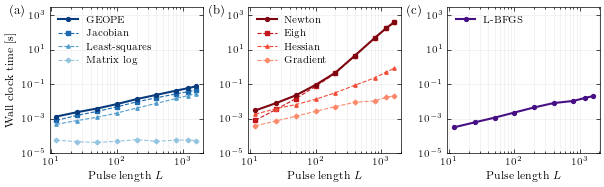

In [4]:
wide = cost_df.pivot(index="L", columns="piece", values="seconds")[list(PIECES)]

blues, reds, purples = plt.cm.Blues, plt.cm.Reds, plt.cm.Purples
#: ``(shade, marker)`` per constituent, largest piece first. The total keeps the
#: darkest shade *and* the only solid line, so the line style is the one thing a
#: reader has to decode: solid is a whole iteration, dashed is a piece of one.
PIECE_STYLES = ((0.78, "s"), (0.58, "^"), (0.40, "D"))
TOTAL_SHADE = 0.95

#: One panel per algorithm: ``(title, colour family, pieces, display names)``.
PANELS = (
    (
        "GEOPE",
        blues,
        GEOPE_PIECES,
        {
            "GEOPE: Jacobian": "Jacobian",
            "GEOPE: logm": "Matrix log",
            "GEOPE: lstsq": "Least-squares",
        },
    ),
    (
        "Newton",
        reds,
        NEWTON_PIECES,
        {
            "Newton: gradient": "Gradient",
            "Newton: Hessian": "Hessian",
            "Newton: eigh solve": "Eigh",
        },
    ),
    ("L-BFGS", purples, LBFGS_PIECES, {"LBFGS: gradient": "Fidelity gradient"}),
)
#: Below this the pieces sit on a fixed dispatch floor rather than on their
#: arithmetic, so every exponent in the legends is fitted to L >= 100.
FIT_FROM = 100
YLIM = (1e-5, 3e3)

fig = plt.figure(figsize=(TWO_COLUMN, 1.9))
gs = fig.add_gridspec(1, 3, wspace=0.30)
axes = [fig.add_subplot(gs[0, 0])]
axes.extend([fig.add_subplot(gs[0, i], sharey=axes[0]) for i in range(1, 3)])

for index, (ax, (name, family, pieces, names)) in enumerate(zip(axes, PANELS)):
    steps = wide.index.to_numpy(float)
    total = wide[pieces].sum(axis=1).to_numpy(float)
    # Largest constituent first, so the legend reads as the argument does and in
    # the same order as the share table below.
    ordered = sorted(pieces, key=lambda p: -float(wide[p].iloc[-1]))

    # A one-piece method has nothing to break out: its constituent and its
    # total are the same curve, and drawing both would put a dashed line under
    # a solid one and a redundant entry in the legend.
    for (shade, marker), piece in zip(PIECE_STYLES, ordered if len(pieces) > 1 else ()):
        values = wide[piece].to_numpy(float)
        # The per cent the line cannot show: two nearly parallel lines a fifth
        # of a decade apart are a 63/37 split, which is not something a reader
        # should have to do in their head.
        share = 100.0 * values[-1] / total[-1]
        _coefficients, label = power_fit(names[piece], steps, values, FIT_FROM)
        ax.loglog(
            steps,
            values,
            color=family(shade),
            ls="--",
            lw=0.8,
            marker=marker,
            ms=2.4,
            zorder=3,
            label=rf"{label}",
        )

    _coefficients, label = power_fit(name, steps, total, FIT_FROM)
    ax.loglog(
        steps,
        total,
        color=family(TOTAL_SHADE),
        ls="-",
        lw=1.5,
        marker="o",
        ms=2.8,
        zorder=4,
        label=label,
    )

    ax.set_xlabel(r"Pulse length $L$")
    ax.grid(alpha=0.25, which="both", lw=0.4)
    # Total first, then the constituents largest to smallest. The pieces were
    # drawn in that order and the total last, so the legend is that one handle
    # moved from the back to the front.
    handles, labels = ax.get_legend_handles_labels()
    order = [len(handles) - 1, *range(len(handles) - 1)]
    ax.legend(
        [handles[i] for i in order],
        [labels[i] for i in order],
        loc="upper left",
    ).get_frame().set_linewidth(0.4)
    ax.text(
        -0.26,
        0.95,
        rf"({'abc'[index]})",
        transform=ax.transAxes,
        fontsize=PANEL_LABEL_SIZE,
        zorder=5,
    )

axes[0].set_ylabel("Wall clock time [s]")
axes[0].set_ylim(*YLIM)
axes[0].set_xlim(0.8 * steps.min(), 1.25 * steps.max())

# fig.tight_layout()
# fig.subplots_adjust()
print(save_figure(fig, f"fig2_cost_per_step_n{3}"))
plt.show()